# Внешние датасеты: обзор

Смотрим на два кандидата для обучения классификатора ориентации и сравниваем их с нашим тестом:

* **TextOCR** ([MiXaiLL76/TextOCR_OCR](https://hf.co/datasets/MiXaiLL76/TextOCR_OCR)): реальные кропы слов с фото (Open Images), в основном латиница, лицензия MIT.
* **Bilingual RU-EN** ([tehnik-tehnolog/bilingual-ocr-ru-en-synthetic](https://hf.co/datasets/tehnik-tehnolog/bilingual-ocr-ru-en-synthetic)): синтетические кропы слов и коротких строк, кириллица и латиница, лицензия MIT.

Чтобы не качать всё целиком (~3.4 ГБ), берём по одному parquet-шарду и делаем из него случайную подвыборку. В bilingual строки отсортированы по метке `cyrillic`/`latin`, поэтому «первые N» брать нельзя, только shuffle.

In [1]:
import os, glob, random, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from datasets import load_dataset
from scipy.ndimage import laplace
plt.rcParams['figure.dpi'] = 90
N = 3000
SEED = 0

textocr = load_dataset('MiXaiLL76/TextOCR_OCR', data_files={'train': 'data/train-00000-of-00005.parquet'}, split='train', verification_mode='no_checks')
biling = load_dataset('tehnik-tehnolog/bilingual-ocr-ru-en-synthetic', data_files={'val': 'data/val-00000-of-00001.parquet'}, split='val', verification_mode='no_checks')
print(textocr); print(biling)

textocr_s = textocr.shuffle(seed=SEED).select(range(N))
biling_s = biling.shuffle(seed=SEED).select(range(N))
test_files = sorted(glob.glob('../Test (1)/test/images/*.png'))
random.seed(SEED); test_s = random.sample(test_files, N)

Dataset({
    features: ['image', 'text'],
    num_rows: 18275
})
Dataset({
    features: ['filepath', 'split', 'label', 'text', 'width', 'height', 'aspect_ratio', 'font_name', 'font_size', 'image'],
    num_rows: 40030
})


## 1. Примеры

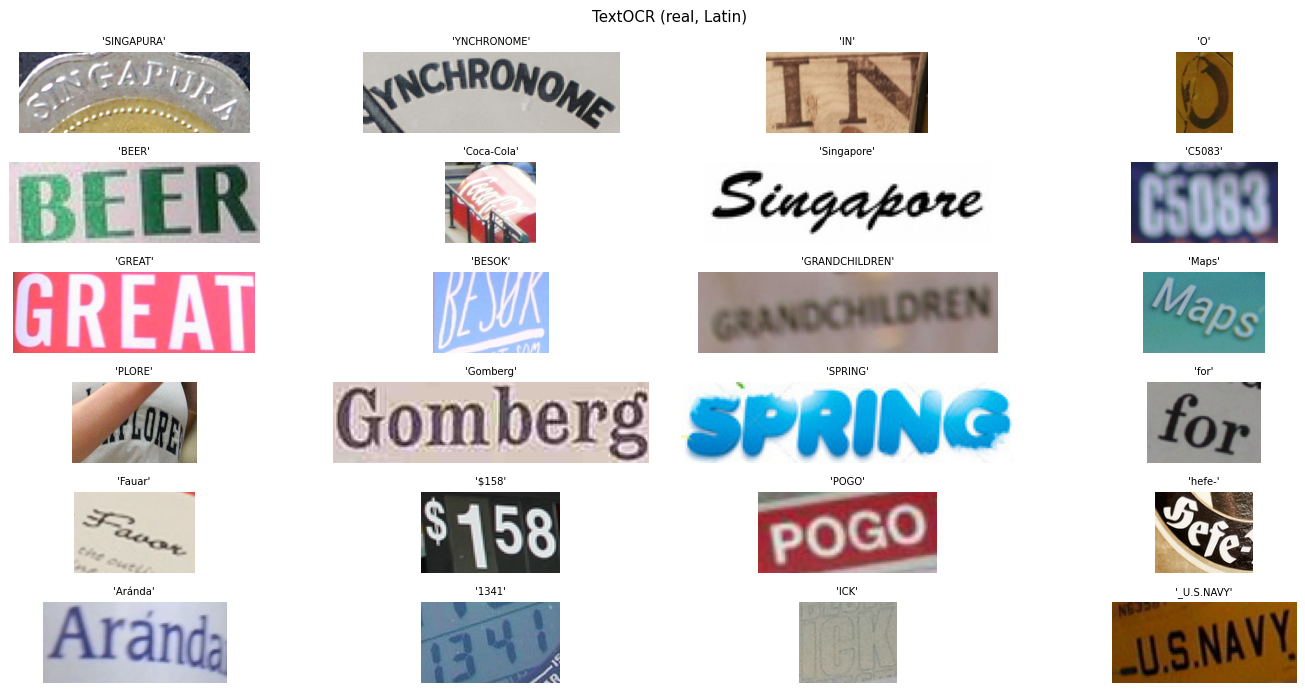

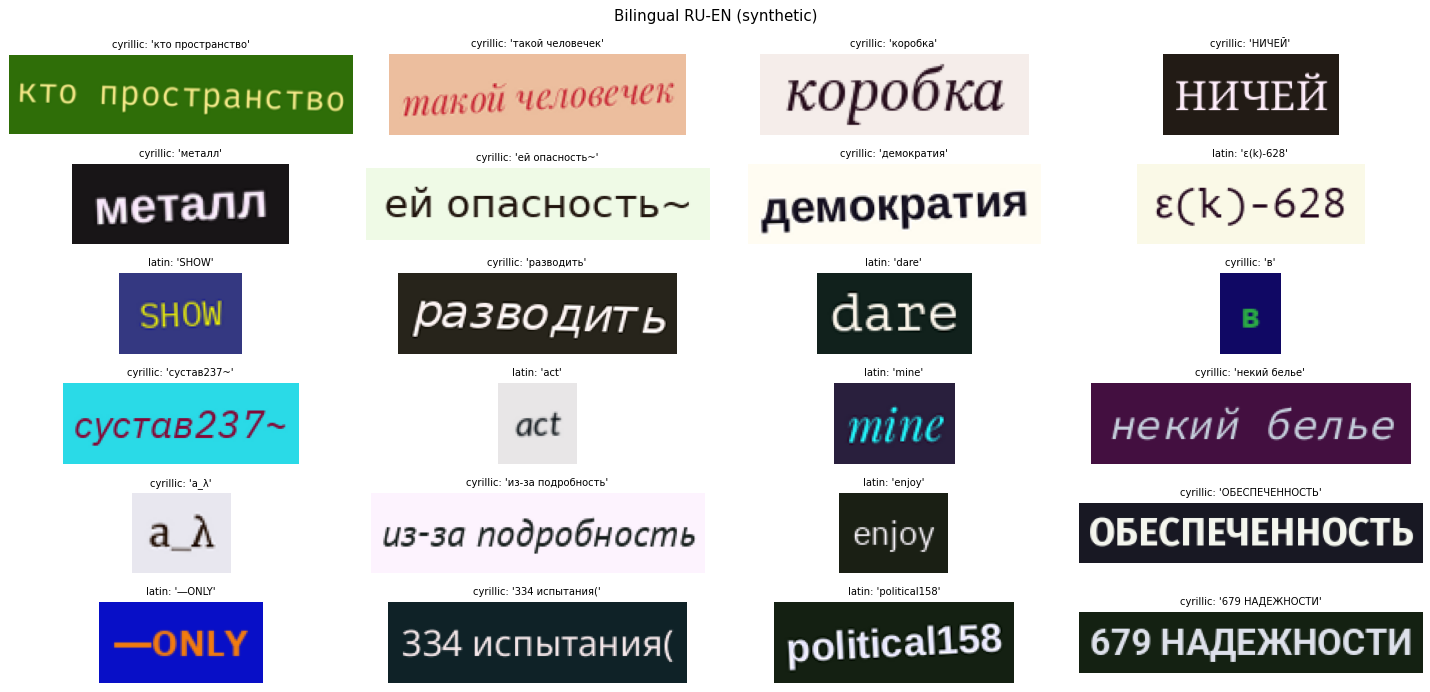

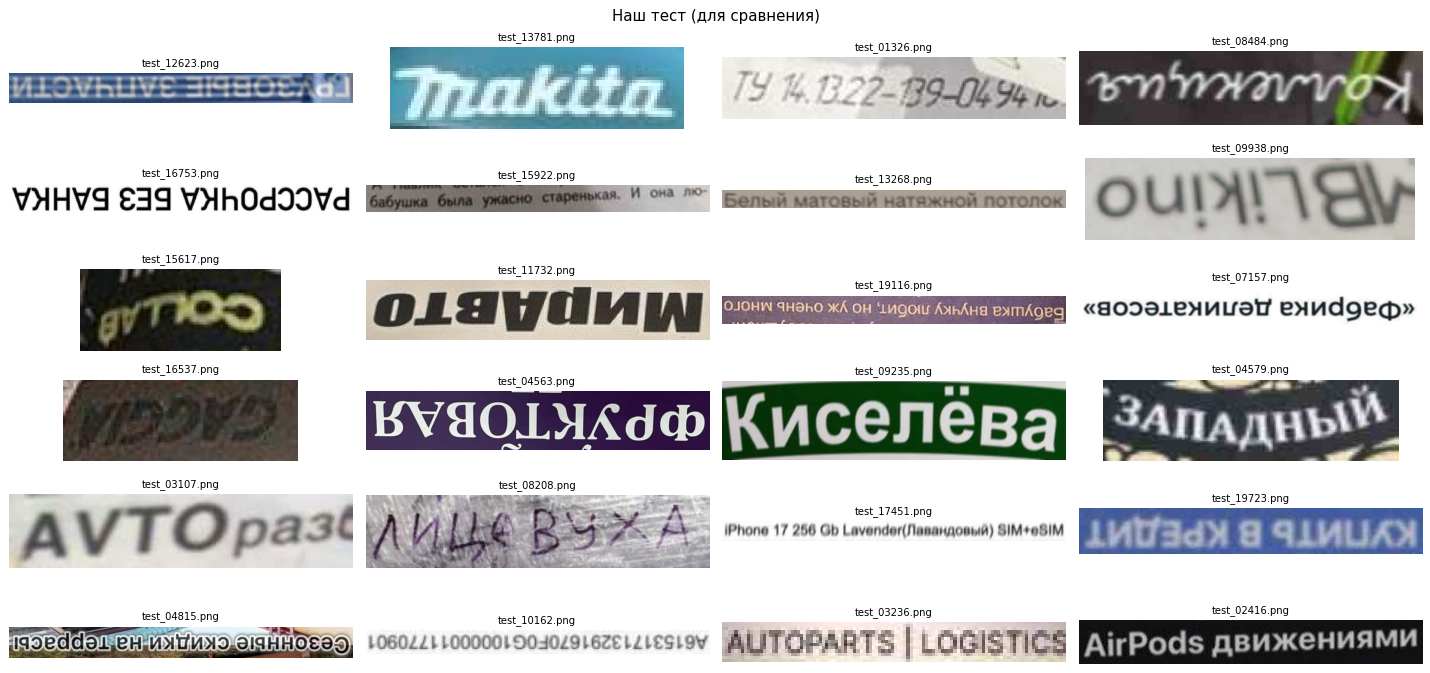

In [2]:
def show_grid(imgs, titles, ncol=4, h=1.3, title=None):
    nrow = int(np.ceil(len(imgs) / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(4 * ncol, h * nrow))
    for i, a in enumerate(np.atleast_1d(ax).ravel()):
        a.axis('off')
        if i < len(imgs):
            a.imshow(imgs[i]); a.set_title(titles[i], fontsize=8)
    if title: fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

k = 24
show_grid([textocr_s[i]['image'] for i in range(k)], [repr(textocr_s[i]['text']) for i in range(k)], title='TextOCR (real, Latin)')
show_grid([biling_s[i]['image'] for i in range(k)], [f"{biling_s[i]['label']}: {biling_s[i]['text']!r}" for i in range(k)], title='Bilingual RU-EN (synthetic)')
show_grid([Image.open(f) for f in test_s[:k]], [os.path.basename(f) for f in test_s[:k]], title='Наш тест (для сравнения)')

## 2. Характеристики

Считаем по каждой картинке:
* геометрию: `w`, `h`, `aspect = w/h`, долю вертикальных кропов (`h > w`);
* яркость и контраст: средний уровень серого и std;
* **полярность**: тёмный текст на светлом фоне (`dark_on_light`), если рамка кропа ярче центра;
* **резкость**: дисперсию лапласиана на картинке, приведённой к высоте 32 px (прокси блюра);
* для датасетов с текстом: длину, число слов, алфавит (`cyr`/`lat`/`digits`/`mixed`) и регистр (`lower`/`upper`/`title`/`mixed`).

In [3]:
CYR = re.compile('[А-Яа-яЁё]'); LAT = re.compile('[A-Za-z]')

def script_of(t):
    c, l = bool(CYR.search(t)), bool(LAT.search(t))
    if c and l: return 'mixed'
    if c: return 'cyr'
    if l: return 'lat'
    return 'digits/sym' if t.strip() else 'empty'

def case_of(t):
    letters = [ch for ch in t if ch.isalpha()]
    if not letters: return 'no_letters'
    if all(ch.islower() for ch in letters): return 'lower'
    if all(ch.isupper() for ch in letters): return 'upper' if len(letters) > 1 else 'title'
    if letters[0].isupper() and all(ch.islower() for ch in letters[1:]): return 'title'
    return 'mixed'

def img_stats(im):
    im = im.convert('RGB'); w, h = im.size
    g = np.asarray(im.convert('L'), np.float32) / 255.
    b = max(1, min(h, w) // 8)
    border = np.concatenate([g[:b].ravel(), g[-b:].ravel(), g[:, :b].ravel(), g[:, -b:].ravel()])
    center = g[h // 4: h - h // 4 or h, w // 8: w - w // 8 or w]
    g32 = np.asarray(im.convert('L').resize((max(8, round(w * 32 / h)), 32), Image.BILINEAR), np.float32) / 255.
    return dict(w=w, h=h, aspect=w / h, vertical=h > w, gray_mean=g.mean(), contrast=g.std(),
                dark_on_light=np.median(border) > center.mean(), sharpness=laplace(g32).var())

def text_stats(t):
    return dict(text_len=len(t), n_words=len(t.split()), script=script_of(t), case=case_of(t))

def describe(ds, name, with_text=True):
    rows = []
    for r in ds:
        d = img_stats(r['image'])
        if with_text: d.update(text_stats(r['text']))
        rows.append(d)
    df = pd.DataFrame(rows); df['source'] = name
    return df

df_t = describe(textocr_s, 'TextOCR')
df_b = describe(biling_s, 'Bilingual')
df_b['font'] = biling_s['font_name']
df_test = describe([{'image': Image.open(f)} for f in test_s], 'Our test', with_text=False)
df = pd.concat([df_t, df_b, df_test], ignore_index=True)

In [4]:
num = ['w', 'h', 'aspect', 'gray_mean', 'contrast', 'sharpness']
summary = df.groupby('source')[num].median().T
summary.loc['vertical (h>w), %'] = df.groupby('source').vertical.mean() * 100
summary.loc['dark_on_light, %'] = df.groupby('source').dark_on_light.mean() * 100
summary.loc['h < 20px, %'] = df.groupby('source').h.apply(lambda s: (s < 20).mean() * 100)
summary[['Our test', 'TextOCR', 'Bilingual']].round(2)

source,Our test,TextOCR,Bilingual
w,249.00,116.50,119.50
h,42.00,55.00,49.00
aspect,4.96,2.13,2.48
gray_mean,0.56,0.50,0.56
contrast,0.19,0.17,0.19
sharpness,0.02,0.02,0.06
"vertical (h>w), %",0.00,7.70,2.07
"dark_on_light, %",54.33,56.33,51.33
"h < 20px, %",12.03,0.00,0.00


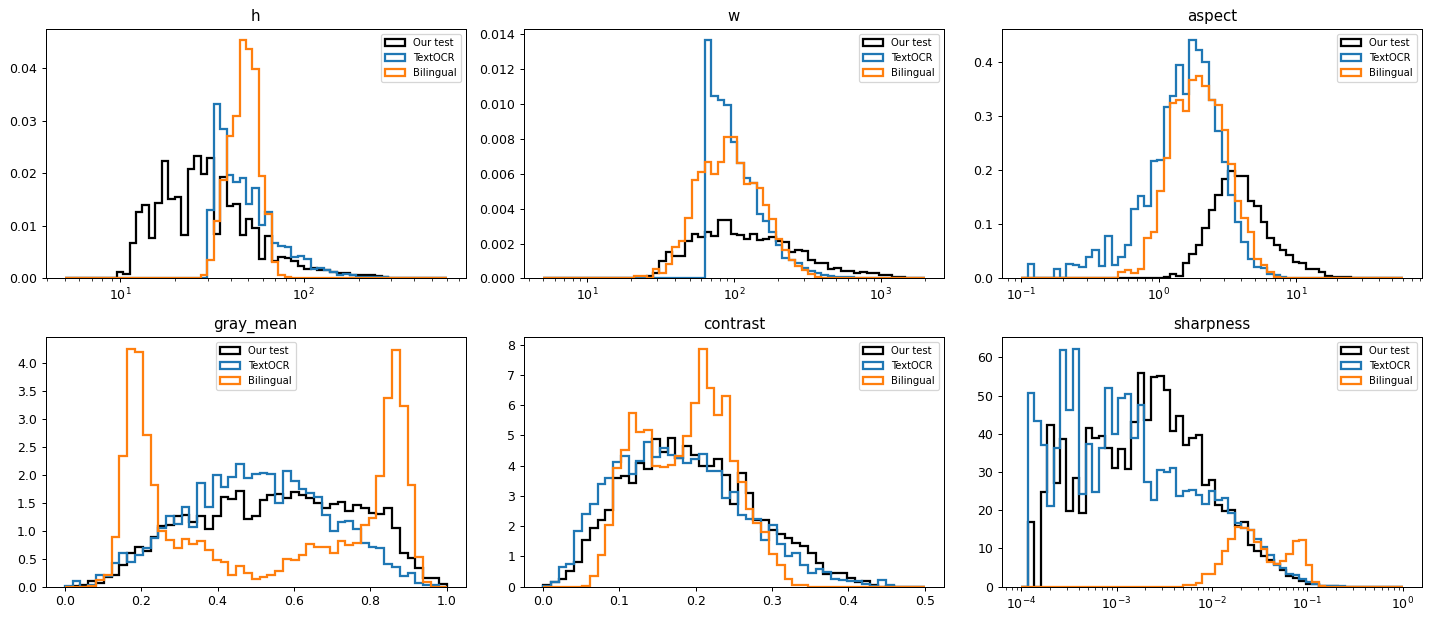

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 7))
specs = [('h', np.logspace(np.log10(5), np.log10(600), 60), True), ('w', np.logspace(np.log10(5), np.log10(2000), 60), True),
         ('aspect', np.logspace(-1, np.log10(60), 60), True), ('gray_mean', np.linspace(0, 1, 50), False),
         ('contrast', np.linspace(0, .5, 50), False), ('sharpness', np.logspace(-4, 0, 60), True)]
colors = {'Our test': 'k', 'TextOCR': 'tab:blue', 'Bilingual': 'tab:orange'}
for a, (c, bins, logx) in zip(ax.ravel(), specs):
    for s, col in colors.items():
        a.hist(df.loc[df.source == s, c], bins=bins, histtype='step', lw=1.8, density=True, label=s, color=col)
    if logx: a.set_xscale('log')
    a.set_title(c); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Текст: алфавит, регистр, длина

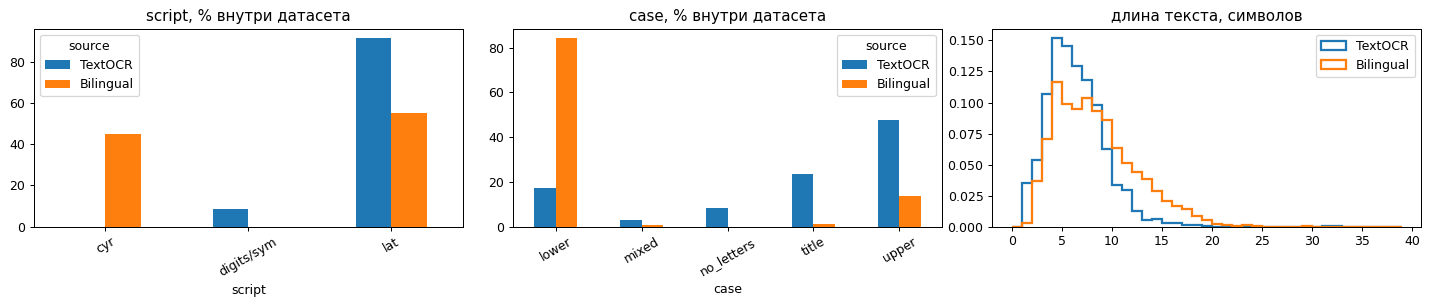

case,lower,mixed,title,upper,All
Bilingual: script \ case,,,,,
cyr,1152,0,2,195,1349
lat,1377,20,39,215,1651
All,2529,20,41,410,3000


case,lower,mixed,no_letters,title,upper,All
TextOCR: script \ case,,,,,,
digits/sym,0,0,252,1,0,253
lat,521,86,0,710,1430,2747
All,521,86,252,711,1430,3000


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
for a, col in zip(ax[:2], ['script', 'case']):
    ct = pd.crosstab(df[col], df.source, normalize='columns')[['TextOCR', 'Bilingual']] * 100
    ct.plot.bar(ax=a); a.set_title(f'{col}, % внутри датасета'); a.tick_params(axis='x', rotation=30)
for s in ['TextOCR', 'Bilingual']:
    ax[2].hist(df.loc[df.source == s, 'text_len'], bins=np.arange(0, 40), histtype='step', lw=1.8, density=True, label=s, color=colors[s])
ax[2].set_title('длина текста, символов'); ax[2].legend()
plt.tight_layout(); plt.show()
display(pd.crosstab(df_b.script, df_b.case, margins=True).rename_axis('Bilingual: script \\ case'))
display(pd.crosstab(df_t.script, df_t.case, margins=True).rename_axis('TextOCR: script \\ case'))

In [7]:
print('Bilingual: шрифтов', df_b.font.nunique())
display(df_b.font.str.replace(r'\.(ttf|otf)$', '', regex=True).value_counts().head(20).to_frame('n'))

Bilingual: шрифтов 72


,n
font,
IBM-Plex-Mono-Regular,55
Arimo-Italic,53
Cousine-Regular,53
Carlito-Bold,52
Manrope-Bold,51
Noto-Serif-Bold,51
JetBrains-Mono-Regular,50
Noto-Sans-Regular,49
Merriweather-Regular,48


## 3. Что может помешать как «upright»-данным

Метку ориентации мы получаем бесплатно: исходный кроп считаем upright, а rot180 от него — перевёрнутым. Это работает, только если исходный кроп действительно upright. Проверяем подозрительные случаи в TextOCR:
* вертикальные кропы (`h > w`): часто повёрнутый на ±90° или вертикальный текст;
* очень мелкие кропы (`h < 12`): метка на них почти случайна по смыслу;
* кропы без букв (только цифры и символы): у многих цифр (0, 1, 8, «69») ориентация почти неразличима.

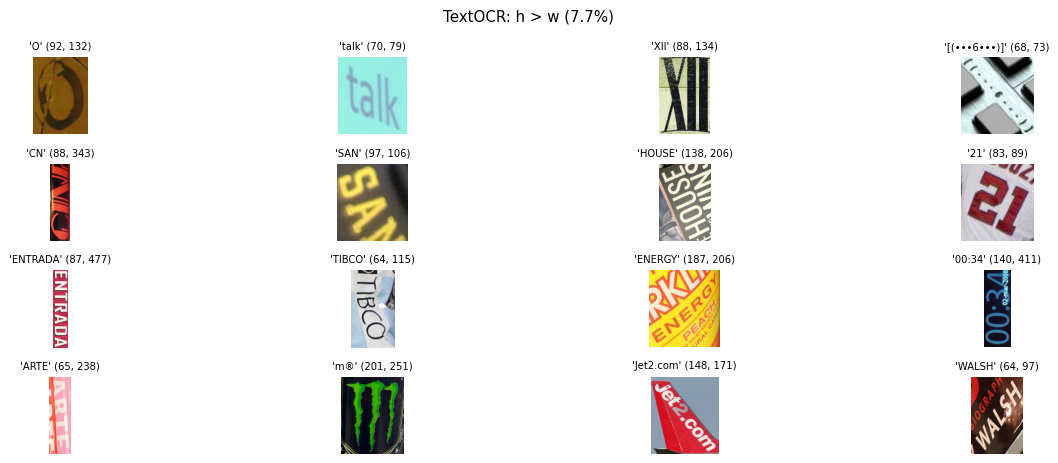

TextOCR: h < 12 px (0.0%) : нет примеров


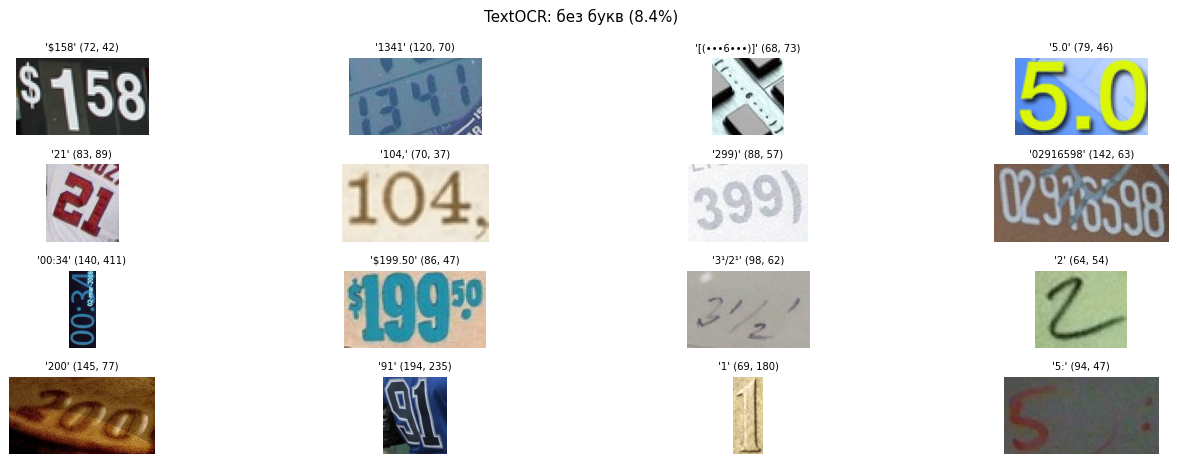

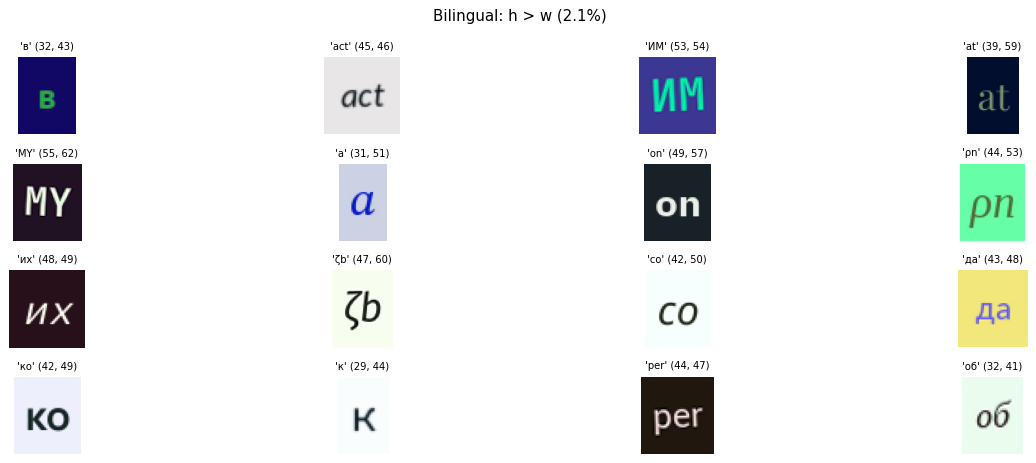

In [8]:
def show_subset(ds, idx, title, k=16):
    idx = list(idx)[:k]
    if not idx: print(title, ': нет примеров'); return
    show_grid([ds[int(i)]['image'] for i in idx], [f"{ds[int(i)]['text']!r} {ds[int(i)]['image'].size}" for i in idx], title=title)

show_subset(textocr_s, df_t.index[df_t.vertical], f'TextOCR: h > w ({df_t.vertical.mean():.1%})')
show_subset(textocr_s, df_t.index[df_t.h < 12], f'TextOCR: h < 12 px ({(df_t.h < 12).mean():.1%})')
show_subset(textocr_s, df_t.index[df_t.script == 'digits/sym'], f"TextOCR: без букв ({(df_t.script == 'digits/sym').mean():.1%})")
show_subset(biling_s, df_b.index[df_b.vertical], f'Bilingual: h > w ({df_b.vertical.mean():.1%})')

## 4. Итог

Подвыборки по 3000 картинок: TextOCR из шарда `train-00000` (18k строк), Bilingual из `val` (40k строк), и 3000 картинок из нашего теста.

| | Наш тест | TextOCR | Bilingual |
|---|---|---|---|
| медиана h, px | 42 | 55 | 49 |
| h < 20 px | **12%** | **0%** | 0% |
| медиана aspect w/h | **5.0** | 2.1 | 2.5 |
| вертикальные (h>w) | 0% | **7.7%** | 2% |
| тёмный текст на светлом | 54% | 56% | 51% |
| резкость (медиана) | 0.02 | 0.02 | **0.06** |

**TextOCR (реальные фото, латиница)**
* По фону, контрасту и резкости совпадает с тестом лучше всех: реальные фото, блюр, окклюдеры, перспектива.
* Все кропы **апскейлены до минимума** (w ≥ 64, h ≥ ~32): на гистограммах видна резкая граница. В тесте 12% кропов ниже 20 px. Значит, нужна аугментация даунскейлом.
* Это **отдельные слова** (aspect ~2), а в тесте чаще строки и фразы (aspect ~5). Можно склеивать соседние слова или учить модель на кропах переменной ширины.
* **7.7% кропов вертикальные или повёрнутые на ±90°**, есть изогнутый текст. Как «upright» они дают шумную метку, их надо фильтровать (как минимум `h > w`).
* ~8% кропов без букв (цифры, символы). У многих из них ориентация почти неразличима.
* Кириллицы нет.

**Bilingual RU-EN (синтетика)**
* Кириллица ~45%, латиница ~55%, 72 шрифта. Для кириллицы это главный источник.
* Слишком «чистая»: однотонный фон (яркость бимодальна), резкость в ~3 раза выше, чем в тесте, нет шума, перспективы и окклюдеров. Нужны сильные аугментации: блюр, JPEG, даунскейл, шум, фоны-текстуры.
* Регистр перекошен в строчные (~84%), КАПСа ~14%. В тесте капса заметно больше, стоит поднять его вес или часть текста переводить в upper при рендере. Бывают экзотические символы (ε, λ, ~), это небольшой шум.

**Вывод:** датасеты дополняют друг друга. TextOCR даёт реализм, Bilingual даёт кириллицу. Ни один не покрывает **реальную кириллицу**, так что для честной валидации на русском по-прежнему нужны кропы из RusTitW.